In [1]:

import pandas as pd
genome_scores_df = pd.read_csv('../data/raw/genome-scores.csv')
display(genome_scores_df.head())
print("number of missing values in genome_scores_df:",genome_scores_df.isnull().sum().sum())
print("number of unique values in movieId:",genome_scores_df['movieId'].nunique())
print("number of lines in genome_scores_df:",genome_scores_df.shape[0])



,movieId,tagId,relevance
0,1,1,0.02500
1,1,2,0.02500
2,1,3,0.05775
3,1,4,0.09675
4,1,5,0.14675


number of missing values in genome_scores_df: 0
number of unique values in movieId: 10381
number of lines in genome_scores_df: 11709768


In [2]:
genome_scores_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 11709768 entries, 0 to 11709767
Data columns (total 3 columns):
 #   Column     Dtype  
---  ------     -----  
 0   movieId    int64  
 1   tagId      int64  
 2   relevance  float64
dtypes: float64(1), int64(2)
memory usage: 268.0 MB


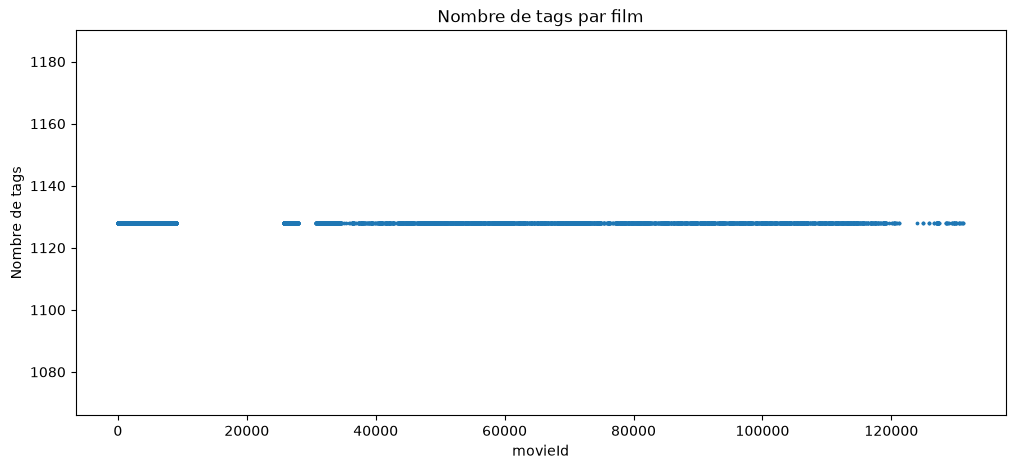

nombre de valeurs uniques dans tags_par_film: 1


In [3]:
import matplotlib.pyplot as plt

tags_par_film = genome_scores_df.groupby("movieId")['tagId'].count()

plt.figure(figsize=(12, 5))
plt.scatter(tags_par_film.index, tags_par_film.values, s=3)
plt.xlabel("movieId")
plt.ylabel("Nombre de tags")
plt.title("Nombre de tags par film")
plt.show()
print("nombre de valeurs uniques dans tags_par_film:",tags_par_film.nunique())

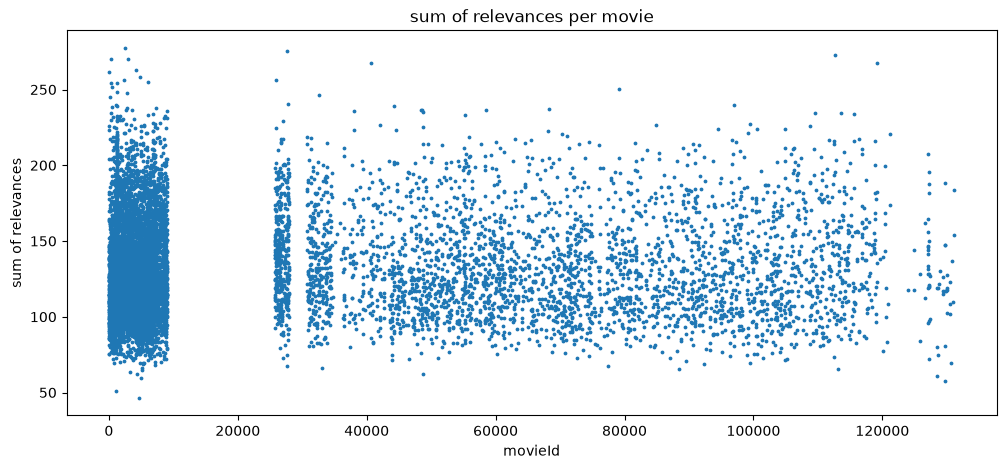

In [4]:
relevances_sum_by_movie = genome_scores_df.groupby("movieId")['relevance'].sum()
plt.figure(figsize=(12, 5))
plt.scatter(relevances_sum_by_movie.index, relevances_sum_by_movie.values, s=3)
plt.xlabel("movieId")
plt.ylabel("sum of relevances")
plt.title("sum of relevances per movie")
plt.show()

# Relevance distribution

movieId
2571     131
2959     119
4226     118
4878     116
318      115
296      114
1089     113
260      113
6016     112
1196     111
50       110
79132    109
32587    106
27773    105
25911    104
Name: relevance, dtype: int64


Text(0.5, 1.0, 'Distribution of relevant tags per movie')

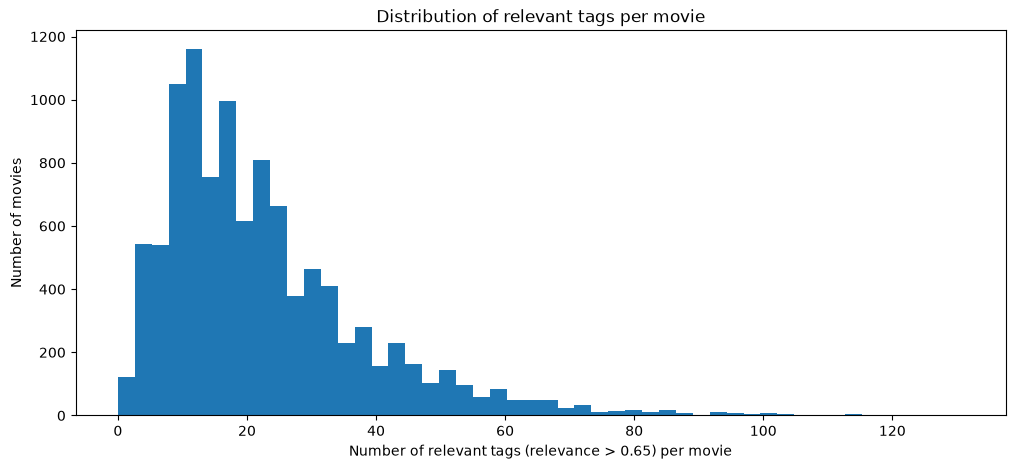

In [5]:
relevances_movies_df = (genome_scores_df['relevance']>0.65).groupby(genome_scores_df['movieId']).sum().sort_values(ascending=False)
print(relevances_movies_df.head(15))
plt.figure(figsize = (12,5))
plt.hist(relevances_movies_df.values, bins=50)
plt.xlabel("Number of relevant tags (relevance > 0.65) per movie")
plt.ylabel("Number of movies")
plt.title("Distribution of relevant tags per movie")

by watching the figure above, we can see that allmots all movies have less than 100 relevant tags (relevance >0.65). Let's see if we can shortlist tags with a 100 top list

number of lines in genome_scores_df: 11709768


,tagId,relevance
0,742,7583.60575
1,646,5504.35025
2,468,5185.66475
3,302,5095.80600
4,452,4729.73175
5,188,4681.79850
6,972,4655.65925
7,971,4433.29050
8,464,4429.74975
9,445,4409.85100


number of lines in tags_top_shortlist: 1128


Text(0.5, 1.0, 'Tags sorted by sum of relevances')

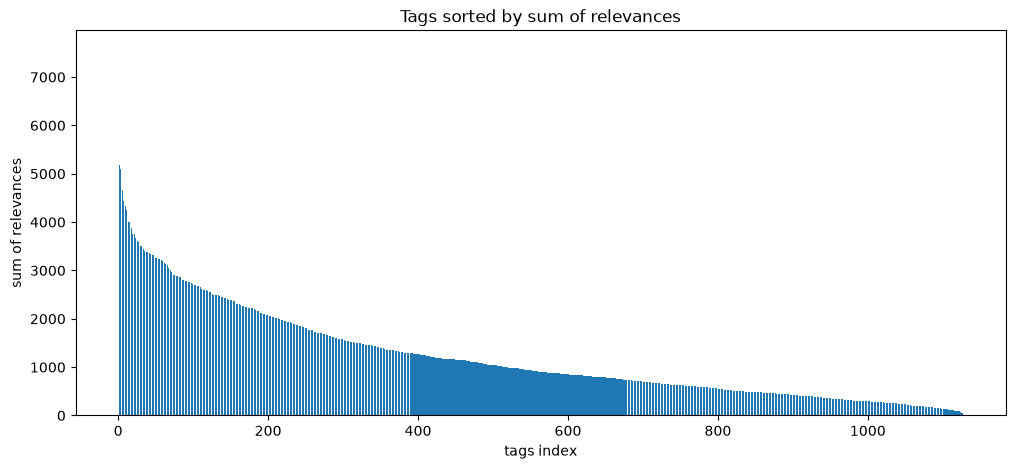

In [22]:
print("number of lines in genome_scores_df:",genome_scores_df.shape[0])
tags_top_shortlist = genome_scores_df.groupby('tagId')['relevance'].sum().sort_values(ascending=False).reset_index()
display(tags_top_shortlist.head(15))
print("number of lines in tags_top_shortlist:",tags_top_shortlist.shape[0])
tags_top_shortlist =tags_top_shortlist.drop('tagId', axis=1)
plt.figure(figsize = (12,5))
plt.bar(tags_top_shortlist.index, tags_top_shortlist['relevance'])
plt.xlabel("tags index")
plt.ylabel("sum of relevances")
plt.title("Tags sorted by sum of relevances")

by looking at areas under the curve, we can see that taking for instance the 100 first tags in terms of relevance sum make us lose too much overall relevance.

In [23]:
genome_scores_df_last.to_parquet('../data/processed/genome_scores_df.parquet')

AttributeError: 'Series' object has no attribute 'to_parquet'